In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
def Acc_Jones(pos_xyz=[[1.,1.,1.]]): #Acceleration due to Lennard-Jones forces in NATURAL UNITS
    """
    Calculate the x, y, and z Lennard-Jones acceleration between two bodies in natural units
    
    Args:
        pos_xyz: the xyz positions of all bodies at a given timestep
        
    return:
        Lennard-Jones acceleration on all particles, 0 if x > 3
    """
    
    dum = pos_xyz.shape[0]
    acc_xyz = np.zeros_like(pos_xyz)
    for pos_ind in range(dum):
        for i in range(dum):
            if pos_ind == i:
                continue
            else:
                diff = pos_xyz[pos_ind] - pos_xyz[i]
                r = np.linalg.norm(diff)
                if r > 3:
                    continue
                elif r == 0:
                    continue
                else:
                    acc = (((r ** (-8)) / 2) - (r ** (-14)))
                    acc_xyz[pos_ind] = acc_xyz[pos_ind] + (acc * diff)
    
    return(acc_xyz)


GE = 398600 #Earth's gravitational parameter, ie earth's mass times the gravitational constant, in km^3 / s^2
GS = 132712440041 #Sun's gravitational parameter

def Acc_Grav(pos_xyz=np.array([[1.,1.,1.]]), Gravs = np.array([1.])): #Acceleration due to Gravity
    """
    Calculate the x, y, and z Gravitatonal acceleration between N bodies in natural units
    
    Args:
        pos_xyz: the xyz positions of all bodies at a given timestep
        Gravs: The gravitational parameter of each of the objects
        
    return:
        Gravitational acceleration on all particles
    """
    
    dum = pos_xyz.shape[0]
    acc_xyz = np.zeros_like(pos_xyz)
    for pos_ind in range(dum):
        for i in range(dum):
            if pos_ind == i:
                continue
            else:
                diff = pos_xyz[pos_ind] - pos_xyz[i]
                r = np.linalg.norm(diff)
                grav_param = Gravs[i]
                
                acc = -grav_param / (r * r * r) #This took forever, but this is secretly r vector over r^3, which becomes 1/r^2 scaling if I cube it
                acc_xyz[pos_ind] = acc_xyz[pos_ind] + (acc * diff) #diff being the r vector in question
                
    return(acc_xyz)

def Euler(pos_xyz=np.array([0.,0.,0.]), vel_xyz=np.array([0.,0.,0.]), dt=0.01, f_law=Acc_Jones, Gravs = np.array([1.])):
    """
    Calculate the next step's position and velocity with Euler's method
    
    Args:
        f_law: the accelerations between all particles caused by a given force law
        dt: the timestep over which Euler's method is applied
        vel_xyz: the velocities of n particles at the current timestep
        pos_xyz: the positions of n particles at the current timestep
        
    return:
        Positions and Velocities of all particles at next timestep
    
    """
    acc_xyz = f_law(pos_xyz, Gravs)
    dx = dt * vel_xyz
    dv = dt * acc_xyz
    new_pos = pos_xyz + dx
    new_vel = vel_xyz + dv
    return(new_pos, new_vel)
    

def Leapfrog(pos_xyz=np.array([0.,0.,0.]), vel_xyz=np.array([0.,0.,0.]), dt=0.01, f_law=Acc_Jones, Gravs = np.array([1.])):
    """
    Calculate the next step's position and velocity with the Leapfrog method
    
    Args:
        f_law: the accelerations between all particles caused by a given force law
        dt: the timestep over which the RK4 method is applied
        vel_xyz: the velocities of n particles at the current timestep
        pos_xyz: the positions of n particles at the current timestep
        
    return:
        Positions and Velocities of all particles at next timestep
    
    """
    acc_xyz = f_law(pos_xyz, Gravs)
    dt_half = dt / 2
    #dx_half = dt_half * vel_xyz
    dv_half = dt_half * acc_xyz
    vel_half = vel_xyz + dv_half
    dx_half = dt * vel_half
    
    new_pos = pos_xyz + dx_half
    new_acc = f_law(new_pos, Gravs)
    new_vel = vel_half + (dt_half * new_acc)
    
    return(new_pos, new_vel)
    
    
#TA Advice: have the entire structure created from the outset, have 2 sub-arrays within the array, and then when you append an equivalent array it should work

def num_integrate(pos_xyz = np.array([[[0.,0.,0.]]]), vel_xyz = np.array([[[0.,0.,0.]]]), method = Euler, dt = 1, f_law = Acc_Jones, t_f = 40., Gravs = np.array([1.])):
    """
    Calculate the x, y, and z positions and velocities over time caused by the Lennard-Jones acceleration between N argon atoms in natural units
    
    Args:
        pos_xyz: Numpy array containing the initial xyz coordinates of N many argon atoms
        vel_xyz: Numpy array containing the initial xyz velocities of N many argon atoms
        method: A step of Euler, RK2, RK4, or some other custom integration method
        dt: size of timestep to use in numerical integration
        f_law: A function calculating a acceleration on one particle due to another for a certain force
        t_f: the amount of time units to iterate over in steps of dt
        
    return:
        Lennard-Jones acceleration on each particle cause by the other, 0 if x > 3
    """
    t_i = np.array([0.])
    t_count = 0.
    while t_i[-1] <= t_f:
        next_pos_vel = method(pos_xyz[-1], vel_xyz[-1], dt, f_law, Gravs)#[0]
        pos_xyz = np.append(pos_xyz, np.array([next_pos_vel[0]]), axis=0)
        vel_xyz = np.append(vel_xyz, np.array([next_pos_vel[1]]), axis=0)
        t_count += dt
        t_i = np.append(t_i, t_count)
    
    return(pos_xyz, vel_xyz, t_i)

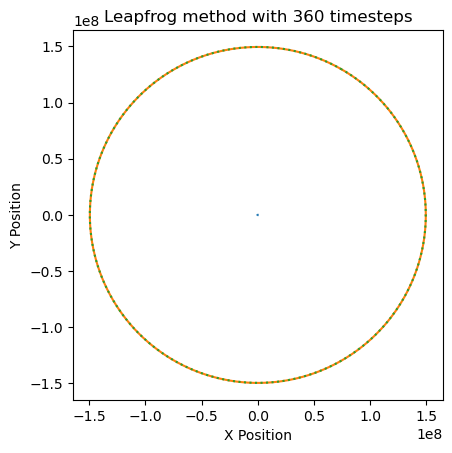

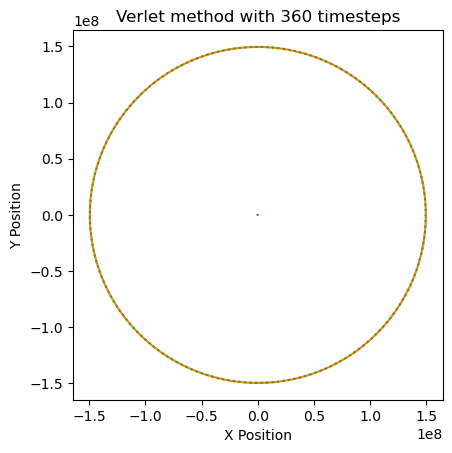

<Figure size 640x480 with 0 Axes>

In [ ]:
#%%time

ES_dist = 1.496 * (10**8) #in km
E_vel = 29.78
methods = [Leapfrog]#, RK4]
method_names = ["Leapfrog"]#, "RK4"]
#timesteps = [60, 10]#, 0.01]
timesteps = [360]#0, 360]#, 0.01]
#NOTE: The issue might be the timestep size, however my computer can't seem to get away with smaller timesteps before running out of time

timestep_names = [" 360"]#, " 3600"]#, " 0.01"] #These are in reverse order for some reason
positions = np.array([[[0.,0.,0.], [ES_dist, 0., 0.], [ES_dist/2, (ES_dist * (3 ** (1/2)))/2, 0.]]]) #Sun, Earth, Satellite
velocities = np.array([[[0.,0.,0.], [0., E_vel, 0.], [-E_vel * (3 ** (1/2)) / 2, E_vel / 2, 0.]]]) #Sun, Earth, Satellite
#t_f = 2.628 * (10 ** 6)
t_f = (6/5) * 2.628 * (10 ** 7) #Change this to get different lengths over which we're integrating

GE = 398600 #Earth's gravitational parameter, ie earth's mass times the gravitational constant, in km^3 / s^2
GS = 132712440041 #Sun's pravitational parameter
Gravs = np.array([GS, GE, 0])

object_indices = [0, 1, 2]

#print(positions)
#for i in range(2): print(i)
for i in range(len(methods)):
    for j in range(len(timesteps)):
        motion = num_integrate(positions, velocities, methods[i], timesteps[j], Acc_Grav, t_f, Gravs)
        
        for k in range(len(object_indices)):    
        
            #The more proper way to do this is probably with another for loop but that's way slower on my end
            if k == 2:
                plt.plot(motion[0][:,k,0], motion[0][:,k,1], linestyle = 'dotted')
            
            else:
                plt.plot(motion[0][:,k,0], motion[0][:,k,1])
            
            plt.xlabel("X Position")
            plt.ylabel("Y Position")
            plt.title(method_names[i] + " method with" + timestep_names[j] + " timesteps")
            plt.axis('scaled')
        
        plt.show()
        plt.clf()
        
        #motion = num_integrate(positions, velocities, methods[i], timesteps[j], Acc_Grav, t_f, Gravs)
        
        #The more proper way to do this is probably with another for loop but that's way slower on my end
        
        #plt.plot(motion[0][:,0,0], motion[0][:,0,1])
        #plt.plot(motion[0][:,1,0], motion[0][:,1,1])
        #plt.plot(motion[0][:,2,0], motion[0][:,2,1], linestyle = 'dotted')
        #plt.xlabel("X Position")
        #plt.ylabel("Y Position")
        #plt.title(method_names[i] + " method with" + timestep_names[j] + " timesteps")
        #plt.axis('scaled')
        #plt.show()
        #plt.clf()

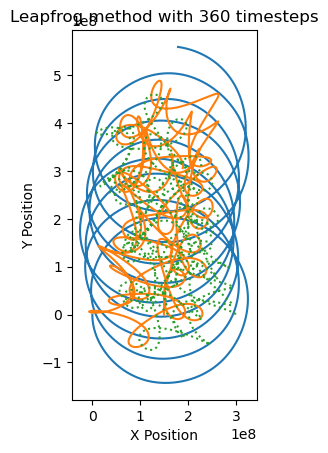

In [ ]:
#For galaxy collision we probably want 2 fields of masses that sum up to the masses of the galaxies we're observing. Elliptical galaxies would be easiest,
#since we should basically be able to model all the masses as having the same initial velocity as one another

#Actually we just need the orbital velocity and then we can just add that to whatever the base velocty would be, so spiral is also fine, would also get around
#The issue that ellipticals don't have a plane in the same way that spirals do, and then we can offset on the third axis to make things more interesting

#General 3 Body Scattering could also be easier than specifically gravitational capture


ES_dist = 1.496 * (10**8) #in km
E_vel = 29.78
methods = [Leapfrog, Verlet]#, RK4]
method_names = ["Leapfrog", "Verlet"]#, "RK4"]
#timesteps = [60, 10]#, 0.01]
timesteps = [360]#0, 360]#, 0.01]
#NOTE: The issue might be the timestep size, however my computer can't seem to get away with smaller timesteps before running out of time

timestep_names = [" 360"]#, " 3600"]#, " 0.01"] #These are in reverse order for some reason
positions = np.array([[[0.,0.,0.], [ES_dist, 0., 0.], [ES_dist * 2, 0., 0.]]]) #Sun, Earth, Fake Moon
velocities = np.array([[[0.,-E_vel,0.], [0., E_vel, 0.], [0., E_vel/8, 0.]]]) #Sun, Earth, Fake Moon
#t_f = 2.628 * (10 ** 6)
t_f = (6/5) * 2.628 * (10 ** 8) #Change this to get different lengths over which we're integrating

GE = 398600 #Earth's gravitational parameter, ie earth's mass times the gravitational constant, in km^3 / s^2
GS = 132712440041 #Sun's pravitational parameter
GM = GE * 0.0123
Gravs = np.array([GS, GS, GS])

#print(positions)
#for i in range(2): print(i)
for i in range(len(methods)):
    for j in range(len(timesteps)):
        motion = num_integrate(positions, velocities, methods[i], timesteps[j], Acc_Grav, t_f, Gravs)
        
        #The more proper way to do this is probably with another for loop but that's way slower on my end
        
        plt.plot(motion[0][:,0,0], motion[0][:,0,1])
        plt.plot(motion[0][:,1,0], motion[0][:,1,1])
        plt.plot(motion[0][:,2,0], motion[0][:,2,1], linestyle = 'dotted')
        plt.xlabel("X Position")
        plt.ylabel("Y Position")
        plt.title(method_names[i] + " method with" + timestep_names[j] + " timesteps")
        plt.axis('scaled')
        plt.show()
        plt.clf()

In [ ]:
#Galaxy Collisions

ES_dist = 1.496 * (10**8) #in km
E_vel = 29.78
methods = [Leapfrog, Verlet]#, RK4]
method_names = ["Leapfrog", "Verlet"]#, "RK4"]
#timesteps = [60, 10]#, 0.01]
timesteps = [360]#0, 360]#, 0.01]
#NOTE: The issue might be the timestep size, however my computer can't seem to get away with smaller timesteps before running out of time

timestep_names = [" 360"]#, " 3600"]#, " 0.01"] #These are in reverse order for some reason
positions = np.array([[[0.,0.,0.], [ES_dist, 0., 0.], [ES_dist/2, (ES_dist * (3 ** (1/2)))/2, 0.]]]) #Sun, Earth, Satellite
velocities = np.array([[[0.,0.,0.], [0., E_vel, 0.], [-E_vel * (3 ** (1/2)) / 2, E_vel / 2, 0.]]]) #Sun, Earth, Satellite
#t_f = 2.628 * (10 ** 6)
t_f = (6/5) * 2.628 * (10 ** 7) #Change this to get different lengths over which we're integrating


M_main = 10 ** 11
#M_perturb = 10 ** 10 #in kg
#G = 6.67 * 10 ** (-11) #with m units
#G_main = 6.6743 #These are in m
#G_perturb = 66.743 #These are in m

G = 6.6743 * 10 ** (-20) #in km
G_main = 6.674 * 10 ** (-9)
G_perturb = 6.674 * 10 **(-10)


#GE = 398600 #Earth's gravitational parameter, ie earth's mass times the gravitational constant, in km^3 / s^2
#GS = 132712440041 #Sun's pravitational parameter

Gravs = np.zeros(14)
Gravs[0] += G_main
Gravs[1] += G_perturb
#Gravs = np.array([G_main, G_perturb, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]) #REMEMBER TO MAKE THIS HOWEVER MANY 0 MASS ORBITING BODIES LONG

#Say it's 4 objects orbiting the main one per ring, and that's 3 rings

object_indices = [0, 1, 2] #Main Galaxy, Perturbing Galaxy, inner 4, middle 4 outer 4

#orbital velocity approxmiately sqrt(G * M / r)
#M_main = 10 ** 11
#r1, r2, r3 = 5, 10, 15 kpc = 1.543 * (10 ** 17), 3.086 * (10 ** 17), 4.629 * (10 ** 17) km
#G = 6.6743 * 10 ** (-20) #in km
r_inner = (1.543 * (10 ** 17))
r_mid = (3.086 * (10 ** 17))
r_outer = (4.629 * (10 ** 17))
vel_inner = np.sqrt((G * M_main)/r_inner)
vel_mid = np.sqrt((G * M_main)/r_mid)
vel_outer = np.sqrt((G * M_main)/r_outer)

initial_sep = 3.086 * (10 **18)

positions = [[0., 0., 0.,], [initial_sep, 0., 0.]]
inner_pos = [[0., r_inner, 0.], [r_inner, 0., 0.,], [0., -r_inner, 0.,], [-r_inner, 0., 0.,]]
mid_pos = [[0., r_mid, 0.], [r_mid, 0., 0.,], [0., -r_mid, 0.,], [-r_mid, 0., 0.,]]
outer_pos = [[0., r_outer, 0.], [r_outer, 0., 0.,], [0., -r_outer, 0.,], [-r_outer, 0., 0.,]]
positions.extend(inner_pos)#THIS SHOULD WORK, COME BCK HERE

#print(positions)
#for i in range(2): print(i)
for i in range(len(methods)):
    for j in range(len(timesteps)):
        motion = num_integrate(positions, velocities, methods[i], timesteps[j], Acc_Grav, t_f, Gravs)
        
        for k in range(len(object_indices)):    
        
            #The more proper way to do this is probably with another for loop but that's way slower on my end
            plt.plot(motion[0][:,k,0], motion[0][:,k,1])
            
            plt.xlabel("X Position")
            plt.ylabel("Y Position")
            plt.title(method_names[i] + " method with" + timestep_names[j] + " timesteps")
            plt.axis('scaled')
        
        plt.show()
        plt.clf()